# Inference of ABP Velocity
... using approximate Brownian Bridges as a sampling accelerator



# Ground Truths

In [22]:
_GT_DR_  = 0.01
_GT_V_   = 1.
_DT_OBS_ = 1.0
_DT_     = 0.1
_N_OBS_  = 3000
_SIG_OBS_ = 3e-10
_FUTURES_ = 3

# Imports

In [23]:
from numba import njit, prange
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import Tensor as T
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.distributions.normal import Normal
from tqdm import tqdm
from itertools import zip_longest
from ppolib import PPO_Agent
import pickle
import os
from bootstrap_mean_std import bootstrap_mean_std
import scrapbook as sb
from scipy.optimize import curve_fit

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal as mvn
from scipy.stats import binned_statistic_2d
from scipy.ndimage import zoom, gaussian_filter
from scipy.optimize import curve_fit
from tqdm.notebook import tqdm
from random import choice
from inference_tools_ppo import ParticleFilter, crng, HilbertSorter, ConditionedBridge, bridge_logl, ZeroBasedRNG, draw_bridge_level, draw_empirical_ellipsoid, kl_divergence_from_samples
from matplotlib import patches as mpatches
import matplotlib as mpl
from matplotlib import cm as cm

sorter = HilbertSorter(depth=9, dims=2)
bridge_gen = ConditionedBridge()

torch.autograd.set_detect_anomaly(True)

# SDE Equation of Motion

In [24]:
def abp_sde(T0, T1, X0, params):
    
    output_hires = params.get('output_hires', False)
    output_bridge_parameters = params.get('output_bridge_parameters', False)
    use_bridges = params['use_bridges']
    use_tqdm = params.get('use_tqdm', False)
    target_shift_P = params.get('target_shift_PHI', 0.)
    target_slope_P = params.get('target_slope_PHI', 0.)
    spread0 = params['bridge_spread0'] if params['use_spread'] else 0.
    spread1 = params['bridge_spread1'] if params['use_spread'] else 0.
    BridgeGen = params['BridgeGen']
    RNG = params['RNG']
    logDr = params['logDr']
    logv  = params['logv']
    Dr    = np.exp(logDr)
    v     = np.exp(logv)
    _id = params.get('id', -1)
    dt  = params['dt']
    
    X = X0.copy()
    T = T0
    step = 0
    
    if output_hires:
        hires  = [X.copy()]
        hiresT = [T]
        
    n_steps = int((T1 - T0) / dt + 1)
    n_parts = X.shape[0]
    dt_ = (T1 - T0) / n_steps
    
    if use_bridges:
        slope_factor = 1 / (np.sqrt(2 * Dr * dt_))
        shift_factor = 1 / (np.sqrt(2 * Dr * dt_) * v * dt_)
        
        slopeP = (target_slope_P + spread1 * np.random.randn(n_parts)) * slope_factor
        shiftP = (target_shift_P + spread0 * np.random.randn(n_parts)) * shift_factor 
        
        bridge_res_P = BridgeGen.get(n_steps + 1, shiftP, slopeP, ('abpsdePbridgegen', _id, T0, T1), 0.0, RNG)
        
        logl = bridge_logl(np.mean(shiftP), np.mean(slopeP), n_steps + 1) - 2 * np.log(v * np.sqrt(2*Dr*dt))
        reward_logl = bridge_logl(np.mean(shiftP), np.mean(slopeP), n_steps + 1) - bridge_logl(0., 0., n_steps + 1)
        
        wP  = bridge_res_P['w']
        dwP = np.diff(wP, axis=0)
        dwP = np.concatenate([wP[[0],:], dwP])
        ddP = np.diff(dwP, axis=0).T

        w = ddP
        
    else:
        w = RNG.get(('abpsde_full', _id, T0, T1), (n_parts, n_steps), corr=0)
        logl = 0
        reward_logl = 0

    if use_tqdm:  
        R_ = tqdm(range(n_steps))
    else:
        R_ = range(n_steps)
        
    for k in R_:

        ''' Integrate the EOM '''

        dx = np.cos(X[:, 2])
        dy = np.sin(X[:, 2])
        drift = np.stack([dx*v, dy*v, np.zeros_like(dx)], axis=1)

        X[..., -1] += np.sqrt(dt_) * w[..., k] * np.sqrt(2 * Dr)
        X += dt_ * drift
        
        if output_hires:
            hires.append(X.copy())
            hiresT.append(T)
    
    res_dict = dict(X1=X, logl=logl, reward_logl=reward_logl, per_particle_streams=dict())
    
    if output_hires:
        res_dict['per_particle_streams']['hires'] = np.stack(hires, -1)

    if output_bridge_parameters:
        ww = np.cumsum(w, axis=1)
        www = np.cumsum(ww, axis=1)
        bridge_confs = np.stack([ww[:, None, [-1],], www[:, None, [-1],]], axis=1)
        res_dict['per_particle_streams']['bridge_slope'] = bridge_confs

    return res_dict

In [25]:
def abp_run_simple(X0=np.zeros((1, 3)),
                   dt=1e-1, Tout=np.linspace(0, 1, 11),
                   params=None
                  ):   
    
    if params is None:
        params = dict(RNG=crng(),
                      Dr = 1e-2,
                      v = 1,
                      dt = dt,
                      output_hires=True,
                      BridgeGen=bridge_gen,
                      use_tqdm = False,
                     )

    x = [X0[:, 0]]
    y = [X0[:, 1]]
    phi = [X0[:, 2]]
    Told = 0
    for Tmax in Tout:
        params['RNG'].reroll(0)
        sim_res = abp_sde(Told, Tmax, np.stack([x[-1], y[-1], phi[-1]]).T, params)
        Told = Tmax
        x.append(sim_res['X1'][:, 0])
        y.append(sim_res['X1'][:, 1])
        phi.append(sim_res['X1'][:, 2])

    x = np.stack(x[1:])
    y = np.stack(y[1:])
    
    return dict(x=x, y=y)

# Data Generation

Generating the test data, with perfectly straight movement

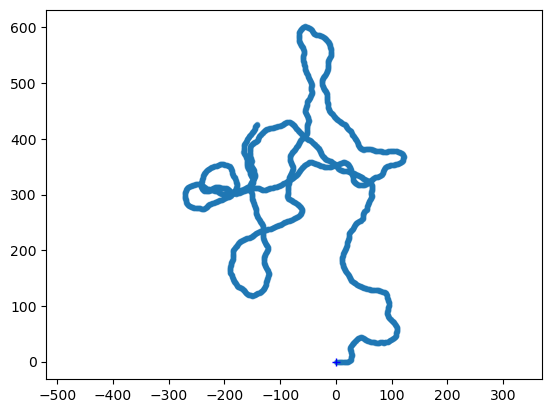

In [26]:
N = 1
dt = _DT_
v = _GT_V_
Tmax = _DT_OBS_ * (_N_OBS_ + _FUTURES_ + 1)

X0 = np.random.uniform(size=(N,3)) * [0, 0, 0]
Tout=np.linspace(_DT_OBS_, Tmax, _N_OBS_ + _FUTURES_ + 1)

# Using Seeds 1234, 12345, 123456, etc.
params = dict(RNG=crng(seed=None),
              logDr = np.log(_GT_DR_),
              logv = np.log(_GT_V_),
              dt = dt,
              output_hires=True,
              BridgeGen=bridge_gen,
              use_tqdm = False,
              target_slope_PHI=0.0,
              target_shift_PHI=0,
              use_bridges = False,
              output_bridge_parameters = True,
              use_spread = False,
             )

res = abp_run_simple(X0, dt, Tout, params)
GT_X = res['x']
GT_Y = res['y']
OBS_X = GT_X + np.random.normal(scale = _SIG_OBS_, size=GT_X.shape) / np.sqrt(2)
OBS_Y = GT_Y + np.random.normal(scale = _SIG_OBS_, size=GT_Y.shape) / np.sqrt(2)

plt.plot(GT_X, GT_Y, '.-', alpha=0.5)
#plt.plot(OBS_X, OBS_Y, 'xr', alpha=0.5)
plt.plot([0], [0], '+b')
plt.gca().axis('equal')
plt.show()

# INFERENCE

## Setup

In [27]:
params = dict(RNG=crng(),
              logDr = np.log(_GT_DR_),
              logv = np.log(_GT_V_),
              dt = _DT_,
              HilbertSort_dims = (0,1),
              HilbertSorter = sorter,
              sigma_observation = _SIG_OBS_,
              output_hires=False,
              output_trajectory=True,
              BridgeGen=bridge_gen,
              HilbertSort_useObservationCenter = False,
              observation_parameters = [],
              reward_range = 1e-15,
              action_range0 = 1.0,
              action_range1 = 1.0,
              deterministic_agent = False,
              provide_absolute_orientation = False,
              provide_absolute_x_location = False,
              provide_absolute_y_location = False,
              provide_swarm_polarity = False,
              base_on_last_observation = False,
              use_bridge_offsets = False,
              rotate_observations_to_swarm = True,
              use_bridges = False,
              output_bridge_parameters = True,
             )

def abp_logl(X, Y, params):
    sigma = params['sigma_observation']
    return np.nansum( -((X - Y) / sigma) ** 2, axis=1)

## Data Preparation and Augementation

In [28]:
Y0 = [dict(T=T,
           Y=np.array([float(X[0]), float(Y[0]), np.nan]),
          )
      for T, X, Y in zip(Tout, OBS_X, OBS_Y)
     ]

# Augment each observation with the offsets to future target points

for y in Y0:
    y['future_x'] = [y['Y'][0]]
    y['future_y'] = [y['Y'][1]]
    
for offset in range(1, _FUTURES_ + 1):    
    for y1, y2 in zip(Y0, Y0[offset:]):
        y1['future_x'].append(y2['Y'][0])
        y1['future_y'].append(y2['Y'][1])

params['futures'] = _FUTURES_
Y0 = Y0[:_N_OBS_] # Cut of the last observations that don't have enough futures

## Mean-Squared-Displacement

0.9997621475903752 1.2449746847447169e-12


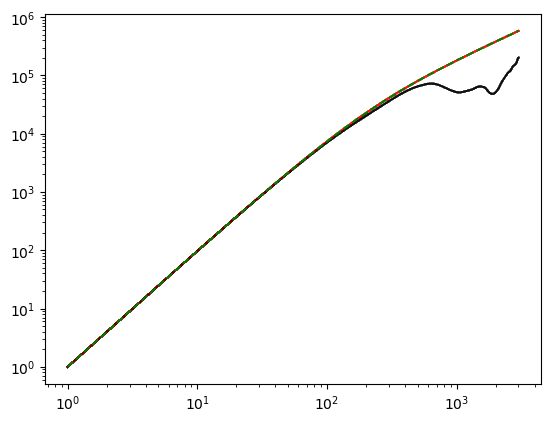

In [29]:
def TAMSD(X, Y, sigma=0, n_bootstrap_samples=1):

    X = X.flatten()
    Y = Y.flatten()

    n = len(X)  # Length of the trajectory
    tamsd_samples = np.zeros((n_bootstrap_samples, n - 1))

    for i in range(n_bootstrap_samples):
        # Add Gaussian noise to the trajectory
        X_noisy = X + np.random.normal(0, sigma, size=n)
        Y_noisy = Y + np.random.normal(0, sigma, size=n)

        for lag in range(1, n):
            displacements = (X_noisy[:-lag] - X_noisy[lag:])**2 + (Y_noisy[:-lag] - Y_noisy[lag:])**2
            tamsd_samples[i, lag - 1] = np.mean(displacements)

    mean_tamsd = np.mean(tamsd_samples, axis=0)
    std_tamsd = np.std(tamsd_samples, axis=0)

    return mean_tamsd, std_tamsd


# BOOTSTRAP MSD
msd_V = []
max_lag = int(1 + 0.1 / _GT_DR_) + 4
def logBBP_MSD(lag, V0):
    DR = _GT_DR_
    return np.log(2*V0**2 / DR**2 * (DR * lag - 1 + np.exp(-DR * lag)) + 2*_SIG_OBS_)

for _ in range(100):
    X = OBS_X.flatten()
    Y = OBS_Y.flatten()
    n = len(OBS_X.flatten())
    X_noisy = X + np.random.normal(0, _SIG_OBS_ * 1, size=n)
    Y_noisy = Y + np.random.normal(0, _SIG_OBS_ * 1, size=n)
    tamsd, _ = TAMSD(X_noisy, Y_noisy)
    lags = (1 + np.arange(len(tamsd))) * _DT_OBS_
    plt.loglog(lags, tamsd, 'k', alpha=0.02)
    w = np.ones(n-1)
    w[max_lag:] = np.inf
    par, cov = curve_fit(logBBP_MSD, lags, np.log(tamsd), sigma=w)
    plt.plot(lags, np.exp(logBBP_MSD(lags, *par)), 'r', alpha=0.02)
    msd_V.append(par)

print(np.mean(msd_V), np.std(msd_V))


plt.plot(lags, np.exp(logBBP_MSD(lags, _GT_V_)), '--g')